In [20]:
#!pip install osmnx geopandas networkx

IndentationError: unexpected indent (3103756133.py, line 2)

In [21]:
#!pip install folium


   -------------------- ------------------- 1/2 [folium]
   ---------------------------------------- 2/2 [folium]



In [22]:
import pandas as pd
import osmnx as ox
import networkx as nx
import folium

df_furto = pd.read_csv('DadosBO_2024_1(FURTO DE CELULAR).xls', sep='\t', encoding='utf-16-le', decimal=',')
df_roubo = pd.read_csv('DadosBO_2024_1(ROUBO DE CELULAR).xls', sep='\t', encoding='utf-16-le', decimal=',')

colunas_selecionadas = [
    'ANO_BO',
    'NUM_BO',
    'DATAOCORRENCIA', 
    'HORAOCORRENCIA', 
    'BAIRRO',
    'CIDADE',
    'LATITUDE',
    'LONGITUDE'
]

C:\Users\mathe\AppData\Local\Temp\ipykernel_21400\617188488.py:7: DtypeWarning: Columns (0: DESDOBRAMENTO, 1: TIPOPESSOA, 2: VITIMAFATAL, 3: NATURALIDADE, 4: NACIONALIDADE, 5: SEXO, 6: DATANASCIMENTO, 7: ESTADOCIVIL, 8: PROFISSAO, 9: GRAUINSTRUCAO, 10: NATUREZAVINCULADA, 11: TIPOVINCULO) have mixed types. Specify dtype option on import or set low_memory=False.
  df_roubo = pd.read_csv('DadosBO_2024_1(ROUBO DE CELULAR).xls', sep='\t', encoding='utf-16-le', decimal=',')


In [16]:
#Reduzido para apenas as coluans excenciais
df_furto = df_furto[colunas_selecionadas]
df_roubo = df_roubo[colunas_selecionadas]

#Classificando cada tipo de crime
df_furto['TIPO_CRIME'] = 'FURTO'
df_roubo['TIPO_CRIME'] = 'ROUBO'

#usanco o concat para transformar em uma tabela unica
df_crimes = pd.concat([df_furto, df_roubo], ignore_index=True)

# Limpando as que nao tem data
df_crimes = df_crimes.dropna(subset=['LATITUDE', 'LONGITUDE'])

In [4]:
df_osasco = df_crimes[df_crimes['CIDADE'] == 'OSASCO'].copy()

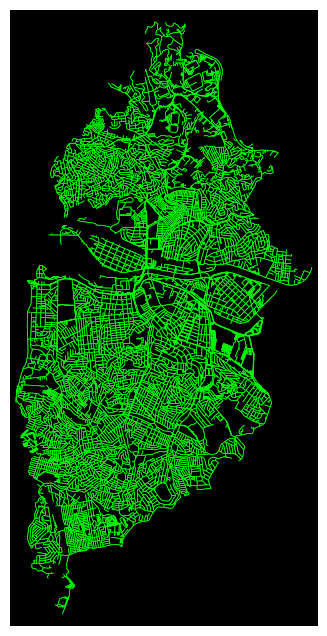

In [5]:

grafo_osasco = ox.graph_from_place('Osasco, São Paulo, Brazil', network_type='walk')

# Plotando o mapa matemático na sua tela!
fig, ax = ox.plot_graph(grafo_osasco, node_size=0, edge_color='#00ff00', edge_linewidth=0.5, bgcolor='black')

In [6]:

#Transformando o Mapa em um Plano Cartesiano
X = df_osasco['LONGITUDE'].astype(float)
Y = df_osasco['LATITUDE'].astype(float)

#Pega o id da rua mais proxima de cada coordenada
ruas_mais_proximas = ox.distance.nearest_edges(grafo_osasco, X, Y)

df_osasco['ID_RUA'] = ruas_mais_proximas

In [7]:
#Transformando em tipo data
df_osasco['DATA_MATEMATICA'] = pd.to_datetime(df_osasco['DATAOCORRENCIA'], format='%d/%m/%Y', errors='coerce')

#To usando essa data como o 'hoje' pq a base nn eh viva, entao estou usando a data mais recente da base como referencia para a regressao de pontos
data_hoje = df_osasco['DATA_MATEMATICA'].max()

df_osasco['DIAS_PASSADOS'] = (data_hoje - df_osasco['DATA_MATEMATICA']).dt.days

#Cada crime tem valor de 100 pontos, porem vai regridindo 1* ao dia
df_osasco['PONTUACAO_PERIGO'] = 100 * (0.99 ** df_osasco['DIAS_PASSADOS'])

tabela_perigo = df_osasco.groupby('ID_RUA')['PONTUACAO_PERIGO'].sum().reset_index()

tabela_perigo = tabela_perigo.sort_values(by='PONTUACAO_PERIGO', ascending=False)
tabela_perigo.head()

,ID_RUA,PONTUACAO_PERIGO
199,"(8002168450, 8002168451, 0)",1711.782090
223,"(8932488412, 8932488412, 1)",1418.215795
68,"(1705116691, 1705116642, 0)",1228.529432
168,"(5187444015, 1757866766, 0)",1176.120000
127,"(1758810387, 1878559550, 0)",1021.749325


In [8]:


# 1. Transformar a tabela de perigo em um Dicionário (o formato que o Grafo entende)
# Isso cria algo como: { (ID_RUA): 100 pontos, (ID_RUA_2): 85 pontos... }
dicionario_perigo = dict(zip(tabela_perigo['ID_RUA'], tabela_perigo['PONTUACAO_PERIGO']))

# 2. Inicializar TODAS as ruas de Osasco com Perigo ZERO (ruas pacíficas)
nx.set_edge_attributes(grafo_osasco, 0.0, 'pontuacao_perigo')

# 3. Injetar a pontuação real nas ruas onde ocorreram assaltos
nx.set_edge_attributes(grafo_osasco, dicionario_perigo, 'pontuacao_perigo')

# 4. A SUA FÓRMULA DE CUSTO: Percorrer cada rua do mapa e calcular o peso final
for u, v, key, data in grafo_osasco.edges(keys=True, data=True):
    distancia_metros = data['length']
    
    # 1 ponto a cada 100 metros
    pontos_distancia = distancia_metros / 100.0 
    
    # Os pontos de crime que acabamos de injetar
    pontos_crime = data['pontuacao_perigo'] 
    
    # Criando o atributo 'custo_total' que o nosso GPS vai usar para decidir a rota
    data['custo_total'] = pontos_distancia + pontos_crime

In [9]:
lon_origem = -46.798797
lat_origem = -23.545189 

lon_destino = -46.794084 
lat_destino = -23.544663

no_origem = ox.distance.nearest_nodes(grafo_osasco, X=lon_origem, Y=lat_origem)
no_destino = ox.distance.nearest_nodes(grafo_osasco, X=lon_destino, Y=lat_destino)





In [10]:
rota_rapida = nx.shortest_path(G=grafo_osasco, source= no_origem, target= no_destino, weight='length')
rota_segura = nx.shortest_path(G=grafo_osasco, source= no_origem, target= no_destino, weight='custo_total')

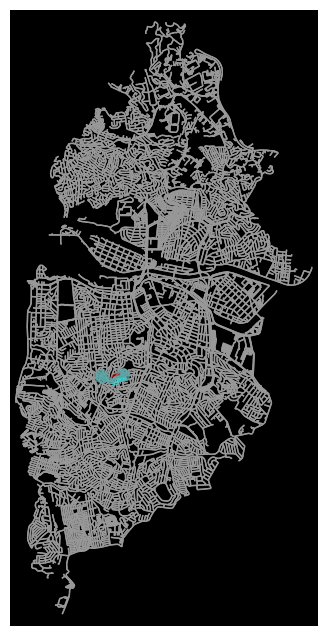

(<Figure size 800x800 with 1 Axes>, <Axes: >)

In [11]:
ox.plot_graph_routes(grafo_osasco, 
                     routes=[rota_rapida, rota_segura], 
                     route_colors=['red', 'cyan'], # Vermelho para a rota normal, Ciano para a segura
                     route_linewidth=4, 
                     node_size=0,
                     bgcolor='black')

In [12]:
# Criando uma função para somar as métricas da rota
def raio_x_da_rota(grafo, rota):
    distancia_total = 0
    perigo_total = 0
    
    # Percorre cada pedaço de rua entre o cruzamento atual (u) e o próximo (v)
    for i in range(len(rota) - 1):
        u = rota[i]
        v = rota[i+1]
        
        # Como o OSMnx permite mãos duplas, pegamos a via principal [0]
        dados_rua = grafo.get_edge_data(u, v)[0]
        
        distancia_total += dados_rua['length']
        perigo_total += dados_rua['pontuacao_perigo']
        
    return distancia_total, perigo_total

# Calculando a Rota Google (Focada em ser curta)
dist_g, perigo_g = raio_x_da_rota(grafo_osasco, rota_rapida)
print(f"🔴 ROTA GOOGLE (Vermelha) -> Distância: {dist_g:.0f} metros | Pontos de Perigo: {perigo_g:.1f}")

# Calculando a Rota Segura (O seu algoritmo)
dist_s, perigo_s = raio_x_da_rota(grafo_osasco, rota_segura)
print(f"🔵 ROTA SEGURA (Ciano)    -> Distância: {dist_s:.0f} metros | Pontos de Perigo: {perigo_s:.1f}")

🔴 ROTA GOOGLE (Vermelha) -> Distância: 633 metros | Pontos de Perigo: 1228.5
🔵 ROTA SEGURA (Ciano)    -> Distância: 741 metros | Pontos de Perigo: 0.0


In [13]:
print("🚨 TOP 5 RUAS MAIS PERIGOSAS DE OSASCO 🚨\n")

# Pegando as 5 primeiras linhas da sua tabela já ordenada
top_5_ruas = tabela_perigo.head(5)

for index, row in top_5_ruas.iterrows():
    # Desempacotando a tupla (Nó de Origem, Nó de Destino, Índice)
    u, v, key = row['ID_RUA']
    pontos = row['PONTUACAO_PERIGO']
    
    # Acessando o "dicionário" de atributos daquela rua específica no Grafo
    dados_rua = grafo_osasco.get_edge_data(u, v, key)
    
    # Nem toda rua no OpenStreetMap tem nome preenchido, então usamos um fallback
    # Às vezes o nome vem como uma lista, então ajustamos isso
    nome_rua = dados_rua.get('name', 'Nome não cadastrado no mapa')
    if isinstance(nome_rua, list):
        nome_rua = nome_rua[0]
        
    # Pegando as coordenadas exatas do cruzamento 'u' para usarmos no nosso GPS
    lat = grafo_osasco.nodes[u]['y']
    lon = grafo_osasco.nodes[u]['x']
    
    print(f"🛑 Rua: {nome_rua}")
    print(f"🔥 Pontuação: {pontos:.0f} pontos")
    print(f"📍 Coordenadas para copiar: {lat}, {lon}")
    print("-" * 50)

🚨 TOP 5 RUAS MAIS PERIGOSAS DE OSASCO 🚨

🛑 Rua: Rodovia Comunicador Silvio Santos - Pista Marginal
🔥 Pontuação: 1712 pontos
📍 Coordenadas para copiar: -23.4811608, -46.7709513
--------------------------------------------------
🛑 Rua: Nome não cadastrado no mapa
🔥 Pontuação: 1418 pontos
📍 Coordenadas para copiar: -23.5411958, -46.7681819
--------------------------------------------------
🛑 Rua: Rua Luís Ferrari
🔥 Pontuação: 1229 pontos
📍 Coordenadas para copiar: -23.5447518, -46.7954629
--------------------------------------------------
🛑 Rua: Avenida João Ventura dos Santos
🔥 Pontuação: 1176 pontos
📍 Coordenadas para copiar: -23.494666, -46.7970358
--------------------------------------------------
🛑 Rua: Rua Doutor Carlos Ubaldino Bueno de Abreu
🔥 Pontuação: 1022 pontos
📍 Coordenadas para copiar: -23.4923353, -46.8015526
--------------------------------------------------


In [24]:


# 1. Achando o centro do mapa para a câmera abrir no lugar certo
no_central = rota_segura[len(rota_segura) // 2]
lat_centro = grafo_osasco.nodes[no_central]['y']
lon_centro = grafo_osasco.nodes[no_central]['x']

# 2. Criando o mapa interativo base (como a tela inicial do Google Maps)
mapa = folium.Map(location=[lat_centro, lon_centro], zoom_start=14, tiles='cartodbpositron')

# 3. Transformando os cruzamentos matemáticos em coordenadas de GPS reais
coord_segura = [[grafo_osasco.nodes[no]['y'], grafo_osasco.nodes[no]['x']] for no in rota_segura]
coord_google = [[grafo_osasco.nodes[no]['y'], grafo_osasco.nodes[no]['x']] for no in rota_rapida]

# 4. Desenhando as duas linhas no mapa
# A rota perigosa (mais curta) em Vermelho
folium.PolyLine(locations=coord_google, color='red', weight=6, opacity=0.7, tooltip='Rota Mais Curta (Perigosa)').add_to(mapa)

# A sua rota inteligente em Azul Ciano (desenhada por cima para destacar)
folium.PolyLine(locations=coord_segura, color='#00d4ff', weight=6, opacity=0.9, tooltip='A Sua Rota Segura').add_to(mapa)

# Exibindo o mapa na tela!
mapa

In [25]:
print("Salvando a inteligência artificial do mapa...")

# Salvando o mapa enriquecido em um arquivo físico
ox.save_graphml(grafo_osasco, filepath='mapa_osasco_seguro.graphml')

print("Sucesso! O mapa 'mapa_osasco_seguro.graphml' foi salvo na mesma pasta do seu projeto.")

Salvando a inteligência artificial do mapa...
Sucesso! O mapa 'mapa_osasco_seguro.graphml' foi salvo na mesma pasta do seu projeto.
